# 03 · Which canopy threshold matches trees

**Question:** which Hansen canopy threshold best matches what people and the best map call trees, and does it differ between ecoregions?

The stage-1 report chose 30 % canopy (the Global Forest Watch convention, close to FAO's forest area). Notebook 02 found that the threshold decides the result more than the product does: where interpreters saw trees, Hansen's canopy has a median of 28 %. This notebook tests every threshold from 0 to 80 % against two references:

* **GLanCE points** (565, interpreters, mostly 2018; notebook 02);
* **ESA WorldCover 2020** at the 56,712 stage-1 points: the map that agrees best with the interpreters in Guinea (86 %, notebook 02), so it gives many more points per ecoregion, but it is a map, not ground truth.

Hansen forest = canopy above the threshold in 2000, and no loss before the reference year. For each threshold, **agreement** is the share of the area where Hansen and the reference say the same (forest or not). The threshold with the highest agreement matches the reference best. All values come from saved tables; no new Earth Engine reads. Notebook 04 uses the threshold chosen here.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

STUDIES = Path.cwd().parent
DATA = STUDIES / "output_datasets" / "lulc_benchmark"                # saved by ../lulc_benchmark.ipynb
OUT = Path.cwd() / "output"
read = lambda key: pd.read_parquet(DATA / f"{key}_h3res7.parquet").set_index("point_id")
THRESHOLDS = list(range(0, 85, 5))
FOREST_ECOREGIONS = ["Guinean forest-savanna", "Western Guinean lowland forests", "Guinean montane forests", "West Sudanian savanna"]

# WorldCover 2020 at the stage-1 points (tree cover and mangroves = trees; water and no data left out)
points = read("sample_points")
hansen, worldcover = read("hansen"), read("worldcover")["2020"]
keep = (hansen.datamask == 1) & worldcover.notna() & ~worldcover.isin([0, 80])
wc = pd.DataFrame({"ecoregion": points.ECO_NAME, "weight": points.weight_km2, "canopy": hansen.treecover2000,
                   "lost": hansen.lossyear.between(1, 20), "trees": worldcover.isin([10, 95])})[keep]

# GLanCE points with their Hansen values (notebook 02); trees = GLanCE level-1 class 5
glance = pd.read_parquet(OUT / "02_glance_points.parquet")
glance["pid"] = np.arange(len(glance))                                # as in notebook 02
glance = glance.merge(pd.read_parquet(OUT / "02_glance_products.parquet"), on="pid")
glance = glance[glance.Glance_Class_ID_level1.isin([1, 3, 4, 5, 6, 7]) & (glance.hansen_datamask == 1)]
ecoregions = gpd.read_file(STUDIES / "output_datasets" / "ecoregions_guinea.gpkg", layer="ecoregions_guinea").to_crs(4326)
glance = gpd.sjoin(gpd.GeoDataFrame(glance, geometry=gpd.points_from_xy(glance.Lon, glance.Lat), crs=4326),
                   ecoregions[["ECO_NAME", "geometry"]], how="left")
year = glance.End_Year.clip(upper=2020)
gl = pd.DataFrame({"ecoregion": glance.ECO_NAME, "weight": 1.0, "canopy": glance.hansen_treecover2000,
                   "lost": (glance.hansen_lossyear > 0) & (glance.hansen_lossyear <= year - 2000),
                   "trees": glance.Glance_Class_ID_level1 == 5})
REFERENCES = {"WorldCover 2020": wc, "GLanCE interpreters": gl}
for name, ref in REFERENCES.items():
    print(f"{name}: {len(ref):,} points, {100 * np.average(ref.trees, weights=ref.weight):.0f} % trees")

WorldCover 2020: 56,438 points, 43 % trees
GLanCE interpreters: 551 points, 49 % trees


## 1 · Agreement by threshold, all of Guinea

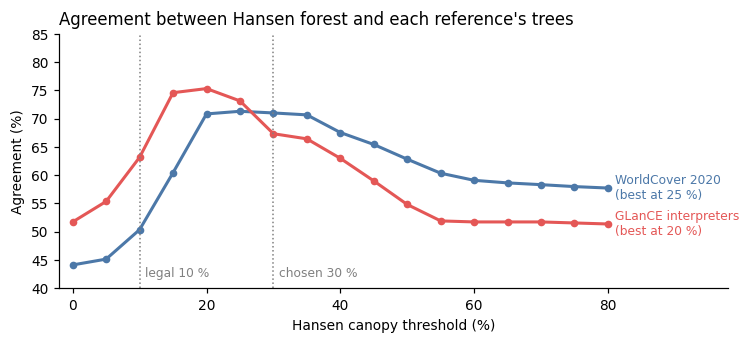

,10,15,20,25,30,35,40,50
WorldCover 2020,50.4,60.4,70.8,71.3,71.0,70.7,67.5,62.8
GLanCE interpreters,63.2,74.6,75.3,73.1,67.3,66.4,63.0,54.8


In [2]:
def agreement(ref):
    # Share of the area (%) where Hansen forest at each threshold matches the reference's trees.
    return pd.Series({t: 100 * np.average(((ref.canopy > t) & ~ref.lost) == ref.trees, weights=ref.weight) for t in THRESHOLDS})


curves = pd.DataFrame({name: agreement(ref) for name, ref in REFERENCES.items()})
fig, ax = plt.subplots(figsize=(7, 3.2))
for (name, curve), colour in zip(curves.items(), ["#4c78a8", "#e45756"]):
    ax.plot(curve.index, curve.values, marker="o", markersize=4, color=colour, linewidth=2)
    ax.text(curve.index[-1] + 1, curve.values[-1], f"{name}\n(best at {curve.idxmax()} %)", color=colour, fontsize=8, va="center")
for t, label in ((10, "legal 10 %"), (30, "chosen 30 %")):
    ax.axvline(t, color="grey", linestyle=":", linewidth=1)
    ax.text(t + 0.8, 42, label, color="grey", fontsize=8)
ax.set_xlim(-2, 98)
ax.set_xlabel("Hansen canopy threshold (%)")
ax.set_ylabel("Agreement (%)")
ax.set_ylim(40, 85)
ax.set_title("Agreement between Hansen forest and each reference's trees", loc="left")
plt.tight_layout(); plt.show()
curves.loc[[10, 15, 20, 25, 30, 35, 40, 50]].round(1).T

**Reading:**

* **WorldCover agrees best with Hansen at 20–35 %**, with a flat top (71 %): it cannot choose inside that range.
* **GLanCE peaks lower, at 15–20 % (75 %), and falls to 67 % at 30 %.** Most of its points are in the West Sudanian savanna, where trees are more open (section 2).
* **The legal 10 % agrees much worse** (50 % with WorldCover, 63 % with GLanCE): at 10 % most wooded savanna is forest, which neither the interpreters nor WorldCover see as trees.

## 2 · By ecoregion

For each ecoregion: the best threshold for each reference, the agreement at the best threshold and at 30 %, and the median Hansen canopy where the reference sees trees. The mangroves are left out (few points, and a small share of the loss). Hansen is in every row: each row compares Hansen, at every threshold, with one reference.

In [3]:
rows = []
for eco in FOREST_ECOREGIONS:
    for name, ref in REFERENCES.items():
        r = ref[ref.ecoregion == eco]
        curve = agreement(r)
        rows.append({"Ecoregion": eco, "Reference": name, "Points": len(r), "Best Hansen threshold (%)": curve.idxmax(),
                     "Agreement at best (%)": curve.max(), "Agreement at Hansen 30 % (%)": curve[30],
                     "Median Hansen canopy where trees (%)": r.loc[r.trees & ~r.lost, "canopy"].median()})
by_ecoregion = pd.DataFrame(rows).set_index(["Ecoregion", "Reference"])
by_ecoregion.round(1).to_csv(OUT / "03_threshold_by_ecoregion.csv")
by_ecoregion.round(1)

Points  \
Ecoregion                       Reference                     
Guinean forest-savanna          WorldCover 2020       30904   
                                GLanCE interpreters     127   
Western Guinean lowland forests WorldCover 2020        5336   
                                GLanCE interpreters      30   
Guinean montane forests         WorldCover 2020        5985   
                                GLanCE interpreters      31   
West Sudanian savanna           WorldCover 2020       13608   
                                GLanCE interpreters     355   

                                                     Best Hansen threshold (%)  \
Ecoregion                       Reference                                        
Guinean forest-savanna          WorldCover 2020                             30   
                                GLanCE interpreters                         25   
Western Guinean lowland forests WorldCover 2020                             30   
                                GLanCE interpreters                         50   
Guinean montane forests         WorldCover 2020                             25   
                                GLanCE interpreters                         25   
West Sudanian savanna           WorldCover 2020                             25   
                                GLanCE interpreters                         15   

                                                     Agreement at best (%)  \
Ecoregion                       Reference                                    
Guinean forest-savanna          WorldCover 2020                       69.0   
                                GLanCE interpreters                   80.3   
Western Guinean lowland forests WorldCover 2020                       71.6   
                                GLanCE interpreters                   83.3   
Guinean montane forests         WorldCover 2020                       71.9   
                                GLanCE interpreters                   74.2   
West Sudanian savanna           WorldCover 2020                       77.3   
                                GLanCE interpreters                   77.2   

                                                     Agreement at Hansen 30 % (%)  \
Ecoregion                       Reference                                           
Guinean forest-savanna          WorldCover 2020                              69.0   
                                GLanCE interpreters                          80.3   
Western Guinean lowland forests WorldCover 2020                              71.6   
                                GLanCE interpreters                          80.0   
Guinean montane forests         WorldCover 2020                              71.6   
                                GLanCE interpreters                          71.0   
West Sudanian savanna           WorldCover 2020                              75.3   
                                GLanCE interpreters                          60.8   

                                                     Median Hansen canopy where trees (%)  
Ecoregion                       Reference                                                  
Guinean forest-savanna          WorldCover 2020                                      37.0  
                                GLanCE interpreters                                  45.0  
Western Guinean lowland forests WorldCover 2020                                      54.0  
                                GLanCE interpreters                                  54.0  
Guinean montane forests         WorldCover 2020                                      37.0  
                                GLanCE interpreters                                  16.0  
West Sudanian savanna           WorldCover 2020                                      20.0  
                                GLanCE interpreters                                  20.0

**Reading:**

* **In the forest-savanna, lowland and montane forests, where 97 % of the loss is, WorldCover's best threshold is 25–30 %**, and agreement at 30 % is within half a point of the best. GLanCE gives the same in the forest-savanna (25 %); in the lowland and montane forests it has only about 30 points each, too few to judge.
* **In the West Sudanian savanna, the best threshold is lower: 25 % with WorldCover, 15 % with GLanCE** (355 points). Trees there are more open: where WorldCover sees trees, the median canopy is 20 %, against 37 % in the forest-savanna and 54 % in the lowland forests.
* So **what counts as trees rises from north to south**, as the vegetation does.

## 3 · Maps

Left: the median Hansen canopy where WorldCover sees trees, per hexagon of about 250 km² (only hexagons with at least 5 tree points). Right: the loss of 2016–2024, by the lowest threshold that counts it: loss on canopy above 30 %, and the loss a threshold of 25 % or 20 % would add.

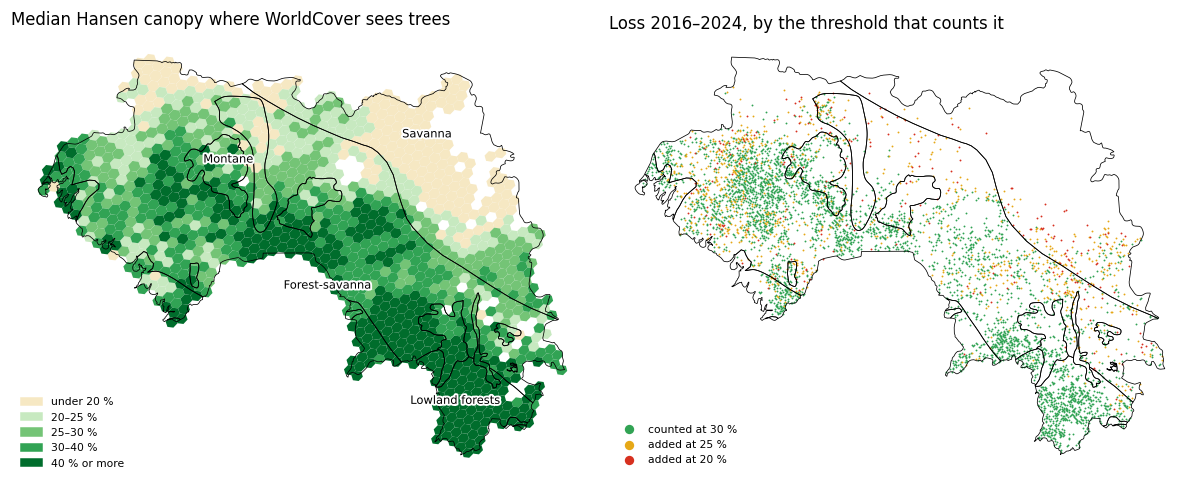

In [4]:
import geopandas as gpd
import matplotlib.patheffects as pe

ecoregions = gpd.read_file(STUDIES / "output_datasets" / "ecoregions_guinea.gpkg", layer="ecoregions_guinea").to_crs(4326)
SHORT_NAMES = {"West Sudanian savanna": ("Savanna", -9.6, 11.6), "Guinean forest-savanna": ("Forest-savanna", -11.0, 9.5),
               "Western Guinean lowland forests": ("Lowland forests", -9.2, 7.9), "Guinean montane forests": ("Montane", -12.4, 11.25)}


def draw_ecoregions(ax, names=True):
    # Ecoregion borders, with short names on the left panel.
    ecoregions.boundary.plot(ax=ax, color="black", linewidth=0.5)
    if names:
        for name, x, y in SHORT_NAMES.values():
            ax.text(x, y, name, fontsize=7.5, ha="center", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    ax.set_axis_off()

import h3
from matplotlib.patches import Patch
from shapely.geometry import Polygon

trees = wc[wc.trees & ~wc.lost].join(points.h3_res5_id)
hexes = trees.groupby("h3_res5_id").canopy.agg(["median", "size"]).query("size >= 5")
hexes = gpd.GeoDataFrame(hexes, crs=4326, geometry=[Polygon([(lon, lat) for lat, lon in h3.cell_to_boundary(c)]) for c in hexes.index])
BANDS = {"under 20 %": "#f6e8c3", "20–25 %": "#c7e9c0", "25–30 %": "#74c476", "30–40 %": "#31a354", "40 % or more": "#006d2c"}
hexes["band"] = pd.cut(hexes["median"], [0, 20, 25, 30, 40, 101], labels=list(BANDS), right=False)

lost = points[hansen.lossyear.between(16, 24) & (hansen.treecover2000 > 20)]
canopy = hansen.treecover2000[lost.index]
counted = pd.Series(np.select([canopy > 30, canopy > 25], ["counted at 30 %", "added at 25 %"], "added at 20 %"), index=lost.index)
COUNTED = {"counted at 30 %": "#31a354", "added at 25 %": "#e6a817", "added at 20 %": "#d7301f"}

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for band, colour in BANDS.items():
    hexes[hexes.band == band].plot(ax=axes[0], color=colour, linewidth=0)
axes[0].legend(handles=[Patch(color=c, label=b) for b, c in BANDS.items()], loc="lower left", frameon=False, fontsize=7)
axes[0].set_title("Median Hansen canopy where WorldCover sees trees", loc="left")
for label, colour in COUNTED.items():
    sub = lost[counted == label]
    axes[1].scatter(sub.lon, sub.lat, s=1.5, color=colour, linewidths=0, label=label)
axes[1].legend(loc="lower left", frameon=False, fontsize=7, markerscale=5)
axes[1].set_title("Loss 2016–2024, by the threshold that counts it", loc="left")
draw_ecoregions(axes[0]); draw_ecoregions(axes[1], names=False)
plt.tight_layout(); plt.show()

**Reading:**

* **The canopy of trees changes gradually from north to south, not at the ecoregion borders.** It is under 20 % in the north-east savanna and 40 % or more in the lowland forests; the forest-savanna alone spans the whole range, from 20 % near the savanna to 40 % in the south and west.
* **The loss a lower threshold adds is mostly in the forest-savanna** (about three quarters of what 25 % adds, section 4), in the north-west and the east, where trees are open. At 20 % it reaches into the savanna. In the lowland forests almost all the loss is counted at 30 % already.

## 4 · What the threshold does to the loss

The mean annual loss 2016–2024 at each threshold, by ecoregion, and with a lower threshold in the West Sudanian savanna only.

In [5]:
def annual_loss(threshold, mask):
    # Mean annual Hansen loss 2016-2024 (km²) of the points in `mask` with canopy above `threshold`.
    forest = mask & (hansen.treecover2000 > threshold)
    return np.mean([points.weight_km2[forest & (hansen.lossyear == y - 2000)].sum() for y in range(2016, 2025)])


loss = pd.DataFrame({f"{t} %": {eco: annual_loss(t, points.ECO_NAME == eco) for eco in points.ECO_NAME.unique()}
                     for t in (15, 20, 25, 30)})
loss.loc["All Guinea"] = loss.sum()
savanna = points.ECO_NAME == "West Sudanian savanna"
loss["30 %, savanna 20 %"] = loss["30 %"]
loss.loc["West Sudanian savanna", "30 %, savanna 20 %"] = annual_loss(20, savanna)
loss.loc["All Guinea", "30 %, savanna 20 %"] = loss.drop("All Guinea")["30 %, savanna 20 %"].sum()
loss = loss.loc[[*FOREST_ECOREGIONS, "Guinean mangroves", "All Guinea"]]
loss.round(0).to_csv(OUT / "03_loss_by_threshold.csv")
loss.round(0)

,15 %,20 %,25 %,30 %,"30 %, savanna 20 %"
Guinean forest-savanna,1796.0,1564.0,1491.0,1138.0,1138.0
Western Guinean lowland forests,393.0,388.0,386.0,370.0,370.0
Guinean montane forests,320.0,266.0,253.0,213.0,213.0
West Sudanian savanna,244.0,97.0,71.0,22.0,97.0
Guinean mangroves,35.0,34.0,34.0,27.0,27.0
All Guinea,2788.0,2349.0,2235.0,1770.0,1845.0


**Reading:**

* **Between 25 % and 30 %, where the references cannot choose, the national loss changes by a quarter** (2,235 against 1,770 km² a year), almost all of it in the forest-savanna. The threshold has to be fixed and stated; the data do not pick one inside this range.
* **A lower threshold in the savanna only adds about 4 % to the national loss** (1,845 against 1,770 km²), because little of the loss is there.

## 5 · What this means

* **Keep one national threshold of 30 %.** In the ecoregions where the loss is, WorldCover's agreement at 30 % is within half a point of the best, and GLanCE agrees as well at 30 % as at 25 % in the forest-savanna; GLanCE's national peak at 15–20 % comes from its savanna points. Since the references cannot choose between 20 and 35 %, the choice rests on other grounds: it is the team's choice, the Global Forest Watch convention, and the threshold of the stage-1 report and the deployed tool.
* **Per-ecoregion thresholds are not worth it now.** Only the savanna would change, and it adds little loss. And the canopy of trees changes gradually, not at the ecoregion borders (section 3), so a threshold per ecoregion would put a step at each border that is not in the landscape. If the savanna's permanent agriculture becomes a focus, 20 % there is the option the references support.
* **State the threshold with every loss figure**, and show 25 % as a sensitivity: it raises the loss by about a quarter.
* **A lower threshold brings Hansen's loss closer to NERF's deforestation plus degradation** (0.68 times it at 30 %, 0.86 times at 25 %; notebook 01). This is not a reason to lower it: NERF uses the legal definition, and the products do not measure the same thing.
* These references see trees, not the legal forest (canopy above 10 %, trees 5 m tall, agricultural land excluded). Testing the legal definition needs interpreters who record canopy cover and land use, as recommended for later in the README.

### References

* Hansen, M.C., et al. (2013). High-resolution global maps of 21st-century forest cover change. *Science* 342, 850–853.
* Stanimirova, R., Tarrio, K., Turlej, K., et al. (2023). A global land cover training dataset from 1984 to 2020. *Scientific Data* 10, 879.
* Xu, P., Tsendbazar, N.-E., Herold, M., et al. (2024). Comparative validation of recent 10 m-resolution global land cover maps. *Remote Sensing of Environment* 311, 114316.
* Zanaga, D., Van De Kerchove, R., Daems, D., et al. (2022). *ESA WorldCover 10 m 2021 v200*. Zenodo. https://doi.org/10.5281/zenodo.7254221